## Frequency Response Practice Problem Generator

In [17]:
import matplotlib.pyplot as plt
import numpy as np
#import control
from numpy import sin, cos, tan, pi
from control import TransferFunction as TF
import control

In [6]:
from krauss_misc import rwkos, txt_mixin
import os, shutil, glob
import pylab_util as PU

In [7]:
import random_bode_generator as rbg

In [8]:
#hide
plt.rcParams['font.size'] = 14

### Get a random TF from `rbg`

In [43]:
G1 = rbg.random_Bode_TF(max_poles = 2)
G1

TransferFunction(
array([1, 0]),
array([1.        , 3.21203839, 1.05282017]),
outputs=1, inputs=1)

### Pick the input frequency

In [44]:
f = 5
w = 2*pi*f
s = 1j*w

In [45]:
t = np.arange(0,5,0.01)

In [46]:
u = np.sin(w*t)

### Find the steady-state response

$$y_{ss}(t) = M \sin (\omega \cdot t + \phi)$$

In [52]:
M = np.abs(G1(s))
M

np.float64(0.03169937378572472)

In [53]:
phi = np.angle(G1(s))
phi

np.float64(-1.468799964276684)

In [54]:
y_ss = M*np.sin(w*t+phi)

### Find the full output from Python

Note that this includes the transient terms

In [50]:
to, y_full = control.forced_response(G1, t, u)

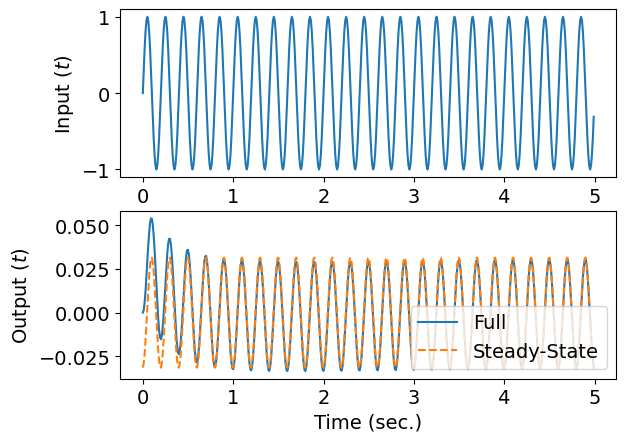

In [51]:
plt.figure()
plt.subplot(211)
plt.ylabel('Input $(t)$')
plt.plot(t,u)
plt.subplot(212)
plt.plot(t,y_full, t, y_ss,'--')
plt.xlabel('Time (sec.)')
plt.ylabel('Output $(t)$')
plt.legend(['Full','Steady-State'],loc=4)